### Die Kunst der Fuge – Lösung Schritt für Schritt

*36. Bundeswettbewerb Informatik (2017/2018), 2. Runde, Aufgabe 1*

Ilona besitzt einen riesigen Haufen Holzklötzchen: Diese haben alle dieselbe Höhe und Tiefe, aber verschiedene Längen.

Ilona möchte eine Mauer bauen. Jede Reihe der Mauer soll aus n Klötzchen bestehen, die die Längen 1 bis n haben und lückenlos
aneinander liegen. Die Stellen zwischen den Klötzchen heißen Fugen. Ilona möchte, dass in der fertigen Mauer niemals zwei Fugen
übereinander liegen, selbst wenn sich mehrere Reihen dazwischen befinden. Außerdem soll ihre Mauer möglichst hoch sein.

Für n = 4 gelingt es ihr recht schnell, eine Mauer mit drei Reihen zu bauen. *(Das Bild des Aufgabenblatts fehlt hier; eine solche
Mauer zeigen wir in Schritt 1.)*

#### Aufgabe

Hilf Ilona, indem du ein Programm schreibst, das nach Eingabe von n eine nach ihren Vorgaben konstruierte, möglichst hohe Mauer ausgibt.
Für n = 10 sollte dein Programm eine Mauer der Höhe 6 ausgeben können. Wie hoch werden die Mauern deines Programms für größere n?

#### Beispieldaten

Eingaben gibt es keine, nur die Zahl n. Im Ordner `beispieldaten` liegt `mauer_n110.xlsx`, eine Musterlösung der Lösungshinweise: eine
Mauer für n = 110 mit 56 Reihen. Wir prüfen sie in Schritt 9 mit unserem eigenen Schiedsrichter.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Zählen (Schubfachprinzip):** Wie viele Stellen für Fugen gibt es, und wie viele Fugen braucht jede Reihe? Daraus folgt sofort, wie
  hoch eine Mauer **höchstens** werden kann.
- **Tiefensuche mit Zurücksetzen (Backtracking):** Stein für Stein anlegen; geht es nicht weiter, den letzten Stein wieder wegnehmen und
  einen anderen probieren. Am einfachsten schreibt man das **rekursiv** (eine Funktion, die sich selbst aufruft).
- **Sackgassen früh erkennen** (englisch *branch and bound*, *pruning*): Wenn schon jetzt feststeht, dass eine Reihe nie mehr fertig
  werden kann, braucht man nicht weiterzusuchen.
- **Zufall und Neustarts:** Eine Suche, die in die falsche Richtung läuft, kommt oft lange nicht wieder heraus. Dann ist es besser, nach
  einer festen Zahl von Schritten abzubrechen und mit einer anderen, zufälligen Reihenfolge neu zu beginnen.
- **Symmetrie:** Eine Mauer, die zur Mitte spiegelbildlich ist, muss man nur zur Hälfte suchen.

**Nützliche Funktionen und Bibliotheken**
- `random.Random(zahl)`: ein Zufallsgenerator, der bei gleicher Zahl immer dieselben Zufallszahlen liefert; `zufall.shuffle(liste)`
  mischt eine Liste, `zufall.randrange(k)` gibt eine Zahl von 0 bis k − 1.
- `liste.sort()` sortiert auch Tupel: zuerst nach dem ersten Eintrag, bei Gleichstand nach dem zweiten. So sortieren wir
  `(rang, reihe)`-Paare nach dem Rang.
- `sys.setrecursionlimit(zahl)`: Python erlaubt normalerweise nur etwa 1000 ineinander geschachtelte Funktionsaufrufe. Unsere Suche geht
  so tief, wie die Mauer Spalten hat; für große n erhöhen wir die Grenze.
- `zipfile` und `re` (beide in Python eingebaut) zum Lesen der Excel-Datei: Eine `.xlsx`-Datei ist ein ZIP-Archiv mit XML-Dateien darin.
- `matplotlib.pyplot` mit `imshow` zum Zeichnen der Mauern: Jede Reihe wird eine Zeile eines Bildes, jede Längeneinheit ein Bildpunkt.

## Die Idee in Worten

**Wie hoch höchstens?** Jede Reihe ist `L = 1 + 2 + … + n = n·(n+1)/2` lang. Fugen können nur an den `L − 1` Stellen 1, 2, …, L − 1
liegen (gemessen vom linken Rand). Jede Reihe hat `n − 1` Fugen, und keine Stelle darf zweimal vorkommen. Also passen höchstens
`(L − 1)/(n − 1)` Reihen übereinander. Das ist genau `(n + 2)/2`; für ungerade n abgerundet: **höchstens `n // 2 + 1` Reihen.** Bei
geradem n hat eine solche Mauer an **jeder** Stelle genau eine Fuge.

**Reihe für Reihe** zu bauen liegt nahe, klappt aber schlecht: Die ersten Reihen verteilen ihre Fugen ungeschickt, und für die letzten ist
kein Platz mehr.

**Spalte für Spalte** (die Idee der Lösungshinweise): Bei geradem n muss jede Stelle genau eine Fuge bekommen. Wir gehen von links nach
rechts. Die erste Stelle ohne Fuge heißt **Cursor**. An den Cursor muss eine Fuge, also muss eine Reihe dort einen Stein so anlegen,
dass er genau am Cursor endet. Hört eine Reihe bei `e` auf, kommt dafür nur der Stein der Länge `Cursor − e` in Frage, und den darf
die Reihe noch nicht haben. Danach rückt der Cursor um eins weiter. Gibt es keine passende Reihe, nehmen wir den letzten Stein
zurück und probieren eine andere Reihe (Backtracking). Zu Beginn bekommt Reihe 1 den Stein 1, Reihe 2 den Stein 2 usw. (eine
**Treppe**), dann haben die ersten Stellen ihre Fugen.

**Schneller wird die Suche** durch drei Ideen der Lösungshinweise:
- **Sackgassen erkennen:** Liegt eine Reihe so weit hinter dem Cursor, dass keiner ihrer übrigen Steine lang genug ist, wird sie nie
  fertig. Dann sofort zurück.
- **Zufällige Reihenfolgen mit Neustarts:** Welche Steinlänge zuerst probiert wird, entscheidet über die Laufzeit. Wir würfeln die
  Reihenfolge, brechen nach `n³/12` Schritten ab und würfeln neu.
- **Spiegeln:** Für `n = 4k + 2` (also 6, 10, 14, …) ist die Zahl der Reihen gerade. Dann bauen wir nur die linke Hälfte, je zwei
  Reihen teilen sich einen Satz Steine, und die rechte Hälfte entsteht durch Spiegeln.

**Ungerade n:** Aus einer Mauer für `n − 1` wird eine für `n`, indem man in jede Reihe hinter den ersten Stein einen Stein der Länge n
schiebt. Die Höhe bleibt gleich, und das ist für ungerades n schon das Höchste.

Der Plan: Schiedsrichter und Zeichnen (Schritt 1), die Schranke (2), dann fünf Versionen der Suche (3–7), ungerade n (8) und alle
Ergebnisse (9).

## Schritt 1: Fugen, Schiedsrichter und Zeichnen

Eine Reihe ist eine Liste von Steinlängen, eine Mauer eine Liste von Reihen. Die Fugen einer Reihe liegen bei den **Teilsummen**: nach dem
ersten Stein, nach den ersten beiden Steinen usw., nur nicht am Ende der Mauer.

Der Schiedsrichter `pruefe` kontrolliert jede Mauer, die wir später bauen: Jede Reihe enthält genau die Längen 1 bis n, und keine Stelle
hat zwei Fugen. In einem Wörterbuch merkt er sich zu jeder Fuge die Reihe, in der sie vorkommt.

[1, 4, 3, 2] Fugen bei [1, 5, 8]
[2, 1, 4, 3] Fugen bei [2, 3, 7]
[4, 2, 3, 1] Fugen bei [4, 6, 9]
Schiedsrichter: ok
Falsche Mauer:  Fuge bei 3 in Reihe 1 und in Reihe 2


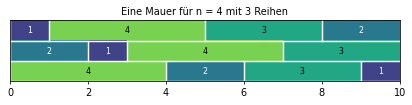

In [ ]:
import random
import sys
import matplotlib.pyplot as plt


def laenge(n):
    """Länge einer Reihe: 1 + 2 + ... + n."""
    return n * (n + 1) // 2


def fugen(reihe):
    """Lagen der Fugen einer Reihe (Teilsummen ohne das Ende der Mauer)."""
    lagen = []
    summe = 0
    for stein in reihe[:-1]:
        summe = summe + stein
        lagen.append(summe)
    return lagen


def pruefe(mauer, n):
    """Schiedsrichter: 'ok' oder eine Beschreibung des ersten Fehlers."""
    reihe_von = {}                          # Fuge -> Nummer der Reihe, in der sie liegt
    for nr in range(len(mauer)):
        if sorted(mauer[nr]) != list(range(1, n + 1)):
            return 'Reihe %d enthält nicht genau die Längen 1 bis %d' % (nr + 1, n)
        for f in fugen(mauer[nr]):
            if f in reihe_von:
                return 'Fuge bei %d in Reihe %d und in Reihe %d' % (f, reihe_von[f] + 1, nr + 1)
            reihe_von[f] = nr
    return 'ok'


def zeige(mauer):
    """Gibt die Steinlängen aus, eine Zeile pro Reihe."""
    for reihe in mauer:
        print(' '.join('%3d' % stein for stein in reihe))


def zeichne(achse, mauer, titel, zahlen=True):
    """Zeichnet die Mauer als Bild: jede Längeneinheit ein Bildpunkt, die Farbe hängt von der Steinlänge ab."""
    n = len(mauer[0])
    h = len(mauer)
    bild = []
    for reihe in mauer:
        zeile = []
        for stein in reihe:
            zeile = zeile + [stein] * stein
        bild.append(zeile)
    achse.imshow(bild, cmap='viridis', vmin=0, vmax=n + 1, aspect='auto', interpolation='nearest',
                 extent=(0, laenge(n), 0, h))      # Reihe 1 oben
    if zahlen:                                     # Fugen als weiße Striche, Längen als Zahlen
        for nr in range(h):
            y = h - 1 - nr
            x = 0
            for stein in mauer[nr]:
                achse.plot([x, x], [y, y + 1], color='white', linewidth=1.5)
                achse.text(x + stein / 2, y + 0.5, str(stein), ha='center', va='center', fontsize=8,
                           color='white' if stein < 0.6 * n else 'black')
                x = x + stein
            achse.plot([0, laenge(n)], [y, y], color='white', linewidth=1.5)
    achse.set_xlim(0, laenge(n))
    achse.set_ylim(0, h)
    achse.set_yticks([])
    achse.set_title(titel, fontsize=10)


mauer4 = [[1, 4, 3, 2],
          [2, 1, 4, 3],
          [4, 2, 3, 1]]
for reihe in mauer4:
    print(reihe, 'Fugen bei', fugen(reihe))
print('Schiedsrichter:', pruefe(mauer4, 4))
print('Falsche Mauer: ', pruefe([[1, 2, 3, 4], [2, 1, 3, 4]], 4))

fig, achse = plt.subplots(figsize=(6, 1.6))
zeichne(achse, mauer4, 'Eine Mauer für n = 4 mit 3 Reihen')
plt.tight_layout()
plt.show()

Die drei Reihen haben zusammen 9 Fugen an den Stellen 1 bis 9, jede Stelle genau einmal. Mehr Reihen gehen bei n = 4 also nicht: Eine
vierte Reihe bräuchte drei weitere Stellen, aber alle sind besetzt. In der falschen Mauer liegen die Fugen nach `1 + 2` und nach `2 + 1`
übereinander.

## Schritt 2: Wie hoch kann eine Mauer höchstens werden?

Jede Reihe hat `n − 1` Fugen, und es gibt nur `L − 1` Stellen. Also passen höchstens `(L − 1) / (n − 1)` Reihen übereinander. Mit
`L = n·(n+1)/2` ist `L − 1 = (n² + n − 2)/2 = (n − 1)·(n + 2)/2`, also

$$\frac{L-1}{n-1} = \frac{n+2}{2} = \frac{n}{2} + 1 .$$

Bei ungeradem n ist das keine ganze Zahl, die Höhe ist dann höchstens `(n + 1)/2`. In Python ist beides `n // 2 + 1`. Bei geradem n hat
die höchste Mauer an **jeder** Stelle genau eine Fuge, bei ungeradem n bleiben `L − 1 − h·(n − 1)` Stellen frei.

Ob es diese Höhe für jedes n auch wirklich gibt, sagt die Rechnung nicht. Das muss unser Programm zeigen. (Für n = 1 gibt es gar keine
Fugen, die Mauer kann beliebig hoch werden; ab n = 2 gilt die Formel.)

In [ ]:
def hoechstens(n):
    """Obere Schranke für die Zahl der Reihen (ab n = 2)."""
    return n // 2 + 1


print(' n     L  Stellen  Fugen/Reihe  höchstens  freie Stellen')
for n in range(2, 13):
    h = hoechstens(n)
    print('%2d  %4d  %7d  %11d  %9d  %13d' % (n, laenge(n), laenge(n) - 1, n - 1, h, laenge(n) - 1 - h * (n - 1)))

 n     L  Stellen  Fugen/Reihe  höchstens  freie Stellen
 2     3        2            1          2              0
 3     6        5            2          2              1
 4    10        9            3          3              0
 5    15       14            4          3              2
 6    21       20            5          4              0
 7    28       27            6          4              3
 8    36       35            7          5              0
 9    45       44            8          5              4
10    55       54            9          6              0
11    66       65           10          6              5
12    78       77           11          7              0


Für n = 10 sind es höchstens 6 Reihen, wie die Aufgabe verlangt. Bei ungeradem n bleiben `(n − 1)/2` Stellen frei.

## Schritt 3: Version 1 – Reihe für Reihe

Der erste Gedanke: eine Reihe nach der anderen bauen. Für jede neue Reihe suchen wir mit einer kleinen Tiefensuche eine Anordnung der
Steine 1 bis n, deren Fugen alle noch frei sind (lange Steine zuerst). Gibt es keine, ist die Mauer fertig.

`neue_reihe` legt Stein für Stein an. Die Menge `belegt` enthält alle Fugen der Reihen darunter. Der letzte Stein endet am Mauerende und
macht keine Fuge mehr, er passt also immer. Damit die Suche nach einer unmöglichen Reihe nicht ewig dauert, zählen wir die Aufrufe und
geben nach `grenze` Aufrufen auf.

In [ ]:
def neue_reihe(n, belegt, grenze):
    """Sucht eine Reihe, deren Fugen nicht in belegt liegen; None, wenn keine gefunden wird."""
    reihe = []
    frei = [True] * (n + 1)          # frei[d]: Stein der Länge d ist noch nicht in der Reihe
    aufrufe = [0]                    # Liste, damit die innere Funktion den Zähler ändern kann

    def weiter(ende):
        aufrufe[0] = aufrufe[0] + 1
        if aufrufe[0] > grenze:
            return False
        if len(reihe) == n - 1:      # der letzte Stein endet am Rand der Mauer
            for d in range(1, n + 1):
                if frei[d]:
                    reihe.append(d)
                    return True
        for d in range(n, 0, -1):    # lange Steine zuerst
            if frei[d] and ende + d not in belegt:
                frei[d] = False
                reihe.append(d)
                if weiter(ende + d):
                    return True
                frei[d] = True       # zurücknehmen
                reihe.pop()
        return False

    if weiter(0):
        return reihe
    return None


def reihe_fuer_reihe(n):
    mauer = []
    belegt = set()
    while True:
        reihe = neue_reihe(n, belegt, 100000)
        if reihe is None:
            return mauer
        mauer.append(reihe)
        for f in fugen(reihe):
            belegt.add(f)


for n in range(2, 13):
    mauer = reihe_fuer_reihe(n)
    print('n = %2d: %d Reihen (höchstens %d), Schiedsrichter: %s' % (n, len(mauer), hoechstens(n), pruefe(mauer, n)))
print()
zeige(reihe_fuer_reihe(10))

n =  2: 2 Reihen (höchstens 2), Schiedsrichter: ok
n =  3: 2 Reihen (höchstens 2), Schiedsrichter: ok
n =  4: 2 Reihen (höchstens 3), Schiedsrichter: ok
n =  5: 3 Reihen (höchstens 3), Schiedsrichter: ok
n =  6: 3 Reihen (höchstens 4), Schiedsrichter: ok
n =  7: 3 Reihen (höchstens 4), Schiedsrichter: ok
n =  8: 3 Reihen (höchstens 5), Schiedsrichter: ok
n =  9: 3 Reihen (höchstens 5), Schiedsrichter: ok
n = 10: 4 Reihen (höchstens 6), Schiedsrichter: ok
n = 11: 4 Reihen (höchstens 6), Schiedsrichter: ok
n = 12: 5 Reihen (höchstens 7), Schiedsrichter: ok

 10   9   8   7   6   5   4   3   2   1
  9   8   7   6   5   4   3   1  10   2
  8  10   7   6   5   2   9   3   1   4
  7   8   6   1  10   5   4   3   2   9


Nur für n = 2, 3 und 5 reicht es für die höchste Mauer, bei n = 10 kommen wir nur auf 4 statt 6 Reihen. Die Mauer zeigt den Grund: Die
erste Reihe legt alle langen Steine nach links, die zweite fast genauso. Ihre Fugen liegen dicht nebeneinander, irgendwann sind zu viele
Stellen in kurzen Abständen besetzt. Wer die Reihen einzeln baut, kann diese Fehler später nicht mehr korrigieren. Wir brauchen eine
Suche, die alle Reihen **gleichzeitig** baut.

## Schritt 4: Version 2 – Spalte für Spalte

Ab jetzt sei n gerade. Dann hat die höchste Mauer `h = n/2 + 1` Reihen und an jeder Stelle genau eine Fuge.

**Der Cursor.** Wir bauen alle h Reihen gleichzeitig von links nach rechts. Der Cursor `c` ist die erste Stelle, die noch keine Fuge hat;
alle Reihen enden links davon. Weil `c` eine Fuge braucht, muss eine Reihe einen Stein anlegen, der genau bei `c` endet. Endet Reihe r bei
`ende[r]`, ist das der Stein der Länge `d = c − ende[r]`. Er kommt in Frage, wenn `d ≤ n` ist und die Reihe ihn noch nicht hat. Danach endet
Reihe r bei `c`, und der Cursor rückt auf `c + 1`. In jedem Schritt entsteht also genau eine Fuge, und zwar am Cursor.

**Der Anfang.** Die Reihenfolge der Reihen ist egal, die ersten Steine sind (wegen der Fugen 1, 2, …) verschieden. Wie die Lösungshinweise
beginnen wir mit einer **Treppe**: Reihe 1 bekommt den Stein 1, Reihe 2 den Stein 2, …, Reihe h den Stein h. Dann haben die Stellen 1 bis h
ihre Fugen, und der Cursor steht bei `h + 1`.

**Das Ende.** Zusammen brauchen die Reihen `h·(n − 1) = L − 1` Fugen. Hat eine Reihe `n − 1` Steine, ist sie fertig bis auf den letzten
Stein; den legen wir nicht mehr an den Cursor (er endet am Rand der Mauer). Steht der Cursor bei `L`, haben alle Stellen eine Fuge. Weil
jede Reihe höchstens `n − 1` Fugen hat und es zusammen `L − 1` sind, hat dann **jede** Reihe genau `n − 1` Steine. Ihr fehlender Stein
passt genau bis zum Rand, denn alle Steine zusammen sind `L` lang.

**Backtracking.** Gibt es für den Cursor keine Reihe, nehmen wir den zuletzt gelegten Stein zurück und probieren an dessen Stelle die
nächste Reihe. `lege(c)` ruft sich dazu selbst auf. Zuerst probieren wir die Reihe, die den **längsten** Stein braucht (die am weitesten
zurückliegt). Wir zählen die Aufrufe von `lege`; sie sind unser Maß für die Rechenzeit.

n =  2: 2 Reihen,       1 Aufrufe, Schiedsrichter: ok
n =  4: 3 Reihen,       7 Aufrufe, Schiedsrichter: ok
n =  6: 4 Reihen,      17 Aufrufe, Schiedsrichter: ok
n =  8: 5 Reihen,     116 Aufrufe, Schiedsrichter: ok
n = 10: 6 Reihen,    1059 Aufrufe, Schiedsrichter: ok
n = 12: 7 Reihen,   10031 Aufrufe, Schiedsrichter: ok
n = 14: 8 Reihen,  203250 Aufrufe, Schiedsrichter: ok

  1   6   5   4   7   8   9   3   2  10
  2   6   7   4   5   3   8   1  10   9
  3   6   5   8   7   9   1  10   2   4
  4   6   7   3   5   8   9  10   1   2
  5   6   7   8   2   4   9   3  10   1
  6   7   8   9   4   3  10   1   2   5


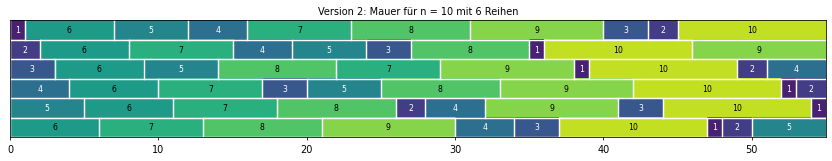

In [ ]:
def spaltenweise(n):
    """Version 2 (n gerade): Rückgabe (Mauer oder None, Zahl der Aufrufe)."""
    h = n // 2 + 1
    L = laenge(n)
    reihen = [[r + 1] for r in range(h)]           # Treppe: Reihe r beginnt mit Stein r + 1
    ende = [r + 1 for r in range(h)]               # wo jede Reihe gerade aufhört
    frei = [[True] * (n + 1) for r in range(h)]    # frei[r][d]: Reihe r hat den Stein d noch nicht verbaut
    for r in range(h):
        frei[r][r + 1] = False
    aufrufe = [0]

    def lege(c):
        """Die Stellen 1 bis c - 1 haben ihre Fuge; jetzt bekommt die Stelle c eine."""
        aufrufe[0] = aufrufe[0] + 1
        if c == L:
            return True                            # alle Stellen haben eine Fuge
        kandidaten = []
        for r in range(h):
            if len(reihen[r]) == n - 1:
                continue                           # bis auf den letzten Stein fertig
            d = c - ende[r]                        # dieser Stein würde genau bei c enden
            if d <= n and frei[r][d]:
                kandidaten.append((d, r))
        kandidaten.sort(reverse=True)              # lange Steine zuerst
        for d, r in kandidaten:
            reihen[r].append(d)                    # anlegen
            frei[r][d] = False
            ende[r] = c
            if lege(c + 1):
                return True
            reihen[r].pop()                        # zurücknehmen
            frei[r][d] = True
            ende[r] = c - d
        return False

    if not lege(h + 1):
        return None, aufrufe[0]
    for r in range(h):                             # der letzte Stein jeder Reihe
        for d in range(1, n + 1):
            if frei[r][d]:
                reihen[r].append(d)
    return reihen, aufrufe[0]


ergebnis_v2 = {}
for n in range(2, 15, 2):
    mauer, aufrufe = spaltenweise(n)
    ergebnis_v2[n] = aufrufe
    print('n = %2d: %d Reihen, %7d Aufrufe, Schiedsrichter: %s' % (n, len(mauer), aufrufe, pruefe(mauer, n)))

mauer10, aufrufe10 = spaltenweise(10)
print()
zeige(mauer10)
fig, achse = plt.subplots(figsize=(12, 2.4))
zeichne(achse, mauer10, 'Version 2: Mauer für n = 10 mit 6 Reihen')
plt.tight_layout()
plt.show()

Für n = 10 steht die verlangte Mauer mit 6 Reihen da, nach 1059 Aufrufen. Die Treppe sieht man links in der Zeichnung. Aber die Zahl der
Aufrufe wächst schnell: Von n = 10 auf n = 12 etwa um den Faktor 10, von 12 auf 14 um den Faktor 20. Für n = 16 haben wir beim Erstellen
des Notebooks nach 3 Millionen Aufrufen aufgegeben.

## Schritt 5: Version 3 – Sackgassen früh erkennen

Version 2 merkt oft viel zu spät, dass es nicht mehr geht. Ein Beispiel: Reihe 3 endet bei 40, der Cursor steht bei 49, und Reihe 3 hat
nur noch die Steine 2, 5 und 7. Alle Stellen von 41 bis 48 haben schon ihre Fugen, also muss der nächste Stein von Reihe 3 mindestens bis 49
reichen, mindestens 9 lang sein. So einen Stein hat sie nicht mehr. Reihe 3 wird nie fertig, aber Version 2 sucht trotzdem rechts weiter,
bis ganz zum Schluss eine Stelle keine Fuge findet. Dazwischen probiert sie unzählige Möglichkeiten durch.

**Die Regel** (wie in den Lösungshinweisen): Hat eine noch nicht fertige Reihe keinen freien Stein, der mindestens `c − ende[r]` lang ist,
geben wir sofort auf. Neu sind außerdem zwei Dinge, die wir für Version 4 brauchen:
- `reihenfolge`: in welcher Reihenfolge die Steinlängen probiert werden. `rang[d]` ist die Stelle von `d` in dieser Liste; die Kandidaten
  sortieren wir als Paare `(rang, reihe)`.
- `grenze`: Nach so vielen Aufrufen bricht die Suche ab (Rückgabe `None`).

In [ ]:
def spaltenweise_v3(n, reihenfolge, grenze):
    """Version 3 (n gerade): mit Sackgassen-Test, wählbarer Reihenfolge und Grenze für die Aufrufe."""
    h = n // 2 + 1
    L = laenge(n)
    rang = [0] * (n + 1)
    for i in range(n):
        rang[reihenfolge[i]] = i                   # kleiner Rang = wird früher probiert
    reihen = [[r + 1] for r in range(h)]
    ende = [r + 1 for r in range(h)]
    frei = [[True] * (n + 1) for r in range(h)]
    for r in range(h):
        frei[r][r + 1] = False
    aufrufe = [0]

    def lege(c):
        aufrufe[0] = aufrufe[0] + 1
        if aufrufe[0] > grenze:
            return False
        if c == L:
            return True
        kandidaten = []
        for r in range(h):
            if len(reihen[r]) == n - 1:
                continue
            d = c - ende[r]
            lang_genug = False                     # NEU: hat die Reihe noch einen Stein der Länge >= d?
            for x in range(d, n + 1):
                if frei[r][x]:
                    lang_genug = True
                    break
            if not lang_genug:
                return False                       # Sackgasse: diese Reihe wird nie fertig
            if d <= n and frei[r][d]:
                kandidaten.append((rang[d], r))
        kandidaten.sort()
        for _, r in kandidaten:
            d = c - ende[r]
            reihen[r].append(d)
            frei[r][d] = False
            ende[r] = c
            if lege(c + 1):
                return True
            reihen[r].pop()
            frei[r][d] = True
            ende[r] = c - d
            if aufrufe[0] > grenze:                # Grenze erreicht: nicht weiter probieren
                return False
        return False

    if not lege(h + 1):
        return None, aufrufe[0]
    for r in range(h):
        for d in range(1, n + 1):
            if frei[r][d]:
                reihen[r].append(d)
    return reihen, aufrufe[0]


ergebnis_v3 = {}
for n in range(2, 15, 2):
    absteigend = list(range(n, 0, -1))             # wie Version 2: lange Steine zuerst
    mauer, aufrufe = spaltenweise_v3(n, absteigend, 10 ** 7)
    ergebnis_v3[n] = aufrufe
    print('n = %2d: %7d Aufrufe (Version 2: %7d), Schiedsrichter: %s' % (n, aufrufe, ergebnis_v2[n], pruefe(mauer, n)))

n =  2:       1 Aufrufe (Version 2:       1), Schiedsrichter: ok
n =  4:       7 Aufrufe (Version 2:       7), Schiedsrichter: ok
n =  6:      17 Aufrufe (Version 2:      17), Schiedsrichter: ok
n =  8:      77 Aufrufe (Version 2:     116), Schiedsrichter: ok
n = 10:     423 Aufrufe (Version 2:    1059), Schiedsrichter: ok
n = 12:    3173 Aufrufe (Version 2:   10031), Schiedsrichter: ok
n = 14:   40035 Aufrufe (Version 2:  203250), Schiedsrichter: ok


Mit derselben Reihenfolge wie Version 2 sind es bei n = 14 nur noch 40035 statt 203250 Aufrufe, etwa ein Fünftel. Für n = 16 findet
Version 3 beim Erstellen des Notebooks eine Mauer nach 1262577 Aufrufen (das dauert im Browser zu lange, deshalb steht es hier nicht in der
Zelle). Gegen das schnelle Wachstum hilft der Test allein nicht.

## Schritt 6: Version 4 – zufällige Reihenfolgen und Neustarts

Die Lösungshinweise beobachten: Welche Reihenfolge der Steinlängen man probiert, ändert die Rechenzeit gewaltig; manche Reihenfolgen
finden die Mauer sofort, andere brauchen Millionen Schritte. Was eine gute Reihenfolge ausmacht, ist nicht zu erkennen. Deshalb:
**Reihenfolge würfeln, höchstens `grenze` Aufrufe suchen, sonst neu würfeln.** Die Hinweise empfehlen als Grenze etwa `n³/12`
(Abschnitt 1.9). Für kleine n ist das sehr wenig (bei n = 10 nur 83), wir nehmen mindestens 1000.

Mit `random.Random(1)` kommen bei jedem Lauf dieselben Zufallszahlen heraus, die Zahlen unten sind also reproduzierbar.

In [ ]:
def grenze_fuer(n):
    return max(1000, n ** 3 // 12)


def mit_neustarts(n, startwert, max_versuche):
    """Version 4: Rückgabe (Mauer, Zahl der Versuche, Aufrufe insgesamt, Reihenfolge des erfolgreichen Versuchs)."""
    zufall = random.Random(startwert)
    gesamt = 0
    for versuch in range(1, max_versuche + 1):
        reihenfolge = list(range(1, n + 1))
        zufall.shuffle(reihenfolge)
        mauer, aufrufe = spaltenweise_v3(n, reihenfolge, grenze_fuer(n))
        gesamt = gesamt + aufrufe
        if mauer is not None:
            return mauer, versuch, gesamt, reihenfolge
    return None, max_versuche, gesamt, None


for n in range(4, 15, 2):
    mauer, versuche, gesamt, reihenfolge = mit_neustarts(n, 1, 1000)
    print('n = %2d: %3d Versuche, %6d Aufrufe insgesamt (Version 3: %6d), Schiedsrichter: %s' %
          (n, versuche, gesamt, ergebnis_v3[n], pruefe(mauer, n)))

n =  4:   1 Versuche,     10 Aufrufe insgesamt (Version 3:      7), Schiedsrichter: ok
n =  6:   1 Versuche,     22 Aufrufe insgesamt (Version 3:     17), Schiedsrichter: ok
n =  8:   2 Versuche,   1084 Aufrufe insgesamt (Version 3:     77), Schiedsrichter: ok
n = 10:   1 Versuche,    160 Aufrufe insgesamt (Version 3:    423), Schiedsrichter: ok
n = 12:   5 Versuche,   4906 Aufrufe insgesamt (Version 3:   3173), Schiedsrichter: ok
n = 14:  12 Versuche,  11592 Aufrufe insgesamt (Version 3:  40035), Schiedsrichter: ok


Bei n = 12 und 14 ist der Zufall etwa so schnell wie Version 3 (4906 gegen 3173 und 11592 gegen 40035 Aufrufe). Bei n = 16 haben wir beim
Erstellen 1745 Versuche gebraucht, zusammen gut 1,7 Millionen Aufrufe, also nicht weniger als Version 3. Für n = 20 waren es 9293
Versuche (9,3 Millionen Aufrufe), für n = 24 fand die Suche auch in 49490 Versuchen (57 Millionen Aufrufe) keine Mauer. Der Grund: Bei Version 3 und 4 muss die Suche jede Reihe auf genau `n − 1` Fugen bringen, und gegen Ende der Mauer
passt fast nichts mehr. Erst die nächste Idee bringt den großen Sprung, allerdings nur für jedes zweite gerade n.

## Schritt 7: Version 5 – Spiegeln (für n = 4, 6, 10, 14, …: n = 4k + 2)

**Die Idee der Lösungshinweise.** Wir koppeln je zwei Reihen zu einem **Paar**. In der linken Hälfte der Mauer bekommen die beiden Reihen
`A` und `B` verschiedene Steine aus **einem gemeinsamen Satz** 1 bis n; ein Stein `m` bleibt übrig. Dann setzen wir

    Reihe 1 = A + [m] + B rückwärts
    Reihe 2 = B + [m] + A rückwärts

Jede volle Reihe enthält jede Länge genau einmal. Reihe 2 ist einfach Reihe 1 **rückwärts gelesen**. Eine rückwärts gelesene Reihe hat
ihre Fugen an den gespiegelten Stellen: aus einer Fuge bei `f` wird eine bei `L − f`. Die rechte Hälfte der Mauer ist also das
Spiegelbild der linken: Die Fugen von Reihe 1 rechts liegen gespiegelt zu den Fugen von B, die von Reihe 2 gespiegelt zu A.

**Warum es keine doppelten Fugen gibt.** Sei `M = (L − 1)/2`. Für `n = 4k + 2` ist L ungerade und M eine ganze Zahl; die linke Hälfte sind
die Stellen 1 bis M, die rechte die Stellen `M + 1` bis `L − 1`. Wir suchen nur die linke Hälfte, mit dem Cursor wie bisher, bis jede
Stelle 1 bis M genau eine Fuge hat. Jede Fuge `f` links liefert ihr Spiegelbild `L − f` rechts, also hat dann auch rechts jede Stelle genau
eine Fuge. Der Mittelstein `m` passt immer: Endet A bei `a` und B bei `b`, ist `a + m + b = L`, weil alle Steine zusammen L lang sind.
Damit reicht der Mittelstein von `a` bis `L − b`, über die Mitte hinweg, und seine Fuge `L − b` ist das Spiegelbild der Fuge `b`.

**Was die Suche anders macht.**
- Ein Paar teilt sich einen Satz Steine (`frei[paar][d]`). Ein Paar ist fertig, wenn es `n − 1` Steine verbaut hat; der letzte freie
  Stein ist dann der Mittelstein. Bei `M + 1` ist die linke Hälfte voll. (Weil es dann `M` Fugen sind und kein Paar mehr als `n − 1`
  Steine links unterbringen kann, hat dann jedes Paar genau `n − 1` verbaut.)
- Der Cursor muss nur bis M laufen, die Suche ist also nur halb so tief. Weil die Zahl der Möglichkeiten mit der Tiefe ungefähr
  exponentiell wächst, ist das viel mehr als ein Faktor 2.
- **Sackgassen beim Paar.** Eine Reihe mit Lücke `c − ende` braucht später einen Stein, der mindestens so lang ist: entweder als
  nächsten Stein oder als Mittelstein (der Mittelstein reicht über die Mitte, also auch über den Cursor). Die beiden Reihen eines Paares
  können aber nicht **denselben** freien Stein dafür nehmen: Nimmt eine ihn als nächsten Stein, ist er nicht mehr frei; als Mittelstein
  für beide geht er nur, wenn das Paar schon fertig ist. Also brauchen wir **zwei verschiedene** freie Steine, einen, der für die größere
  Lücke reicht, und einen zweiten, der für die kleinere reicht. Das ist genau das dritte Beispiel in Abschnitt 1.5 der Lösungshinweise.
  Am einfachsten prüft man das mit den beiden **längsten** freien Steinen des Paares: Der längste muss für die größere Lücke reichen, der
  zweitlängste für die kleinere. Die beiden merken wir uns für jedes Paar (`erster`, `zweiter`) und suchen sie nur neu, wenn sich bei dem
  Paar etwas ändert. Dann kostet der Test pro Paar und Aufruf nur einen Vergleich.

Das Spiegeln braucht eine gerade Zahl von Reihen: `h = n/2 + 1` ist gerade genau für `n = 4k + 2`. Für `n = 4k` ginge es nur, wenn eine Reihe
ihr eigenes Spiegelbild wäre, also vorwärts und rückwärts gleich; dann wäre ihr erster Stein so lang wie ihr letzter.

In [ ]:
sys.setrecursionlimit(5000)                        # die Suche geht bis zu M Aufrufe tief


def spiegelmauer(n, reihenfolge, grenze):
    """Version 5 (n = 4k + 2, n >= 6): Rückgabe (Mauer oder None, Zahl der Aufrufe)."""
    h = n // 2 + 1
    L = laenge(n)
    M = (L - 1) // 2                               # die linke Hälfte: Stellen 1 bis M
    paare = h // 2                                 # Reihen 2p und 2p + 1 bilden das Paar p
    rang = [0] * (n + 1)
    for i in range(n):
        rang[reihenfolge[i]] = i
    reihen = [[r + 1] for r in range(h)]           # die linken Hälften, wieder mit der Treppe
    ende = [r + 1 for r in range(h)]
    frei = [[True] * (n + 1) for p in range(paare)]    # ein Satz Steine pro Paar
    verbaut = [2] * paare
    for r in range(h):
        frei[r // 2][r + 1] = False
    erster = [0] * paare                           # längster freier Stein des Paares
    zweiter = [0] * paare                          # zweitlängster freier Stein des Paares
    aufrufe = [0]

    def zwei_laengste(p):
        """Sucht die beiden längsten freien Steine des Paares p (von n abwärts)."""
        gefunden = []
        x = n
        while len(gefunden) < 2 and x >= 1:
            if frei[p][x]:
                gefunden.append(x)
            x = x - 1
        erster[p] = gefunden[0]
        zweiter[p] = gefunden[1] if len(gefunden) == 2 else 0

    for p in range(paare):
        zwei_laengste(p)

    def lege(c):
        aufrufe[0] = aufrufe[0] + 1
        if aufrufe[0] > grenze:
            return False
        if c == M + 1:
            return True                            # die linke Hälfte ist voll
        kandidaten = []
        for p in range(paare):
            if verbaut[p] == n - 1:
                continue                           # Paar fertig: nur noch der Mittelstein übrig
            luecke1 = c - ende[2 * p]
            luecke2 = c - ende[2 * p + 1]
            # Sackgassen-Test für das Paar: ein freier Stein für die größere Lücke, ein zweiter für die kleinere
            if erster[p] < max(luecke1, luecke2) or zweiter[p] < min(luecke1, luecke2):
                return False
            if frei[p][luecke1]:
                kandidaten.append((rang[luecke1], 2 * p))
            if frei[p][luecke2]:
                kandidaten.append((rang[luecke2], 2 * p + 1))
        kandidaten.sort()
        for _, r in kandidaten:
            p = r // 2
            d = c - ende[r]
            reihen[r].append(d)
            frei[p][d] = False
            verbaut[p] = verbaut[p] + 1
            ende[r] = c
            zwei_laengste(p)
            if lege(c + 1):
                return True
            reihen[r].pop()
            frei[p][d] = True
            verbaut[p] = verbaut[p] - 1
            ende[r] = c - d
            zwei_laengste(p)
            if aufrufe[0] > grenze:
                return False
        return False

    if not lege(h + 1):
        return None, aufrufe[0]
    mauer = []
    for r in range(h):                             # spiegeln
        partner = r + 1 if r % 2 == 0 else r - 1
        mitte = [d for d in range(1, n + 1) if frei[r // 2][d]]   # genau ein Stein
        mauer.append(reihen[r] + mitte + reihen[partner][::-1])
    return mauer, aufrufe[0]


def mit_neustarts_spiegel(n, startwert, max_versuche):
    zufall = random.Random(startwert)
    gesamt = 0
    for versuch in range(1, max_versuche + 1):
        reihenfolge = list(range(1, n + 1))
        zufall.shuffle(reihenfolge)
        mauer, aufrufe = spiegelmauer(n, reihenfolge, grenze_fuer(n))
        gesamt = gesamt + aufrufe
        if mauer is not None:
            return mauer, versuch, gesamt, reihenfolge
    return None, max_versuche, gesamt, None


spiegel_mauern = {}
for n in range(6, 59, 4):
    mauer, versuche, gesamt, reihenfolge = mit_neustarts_spiegel(n, 1, 1000)
    spiegel_mauern[n] = mauer
    print('n = %2d: %2d Reihen, %2d Versuche, %6d Aufrufe insgesamt, Schiedsrichter: %s' %
          (n, len(mauer), versuche, gesamt, pruefe(mauer, n)))
print()
zeige(spiegel_mauern[10])

n =  6:  4 Reihen,  1 Versuche,      9 Aufrufe insgesamt, Schiedsrichter: ok
n = 10:  6 Reihen,  1 Versuche,     29 Aufrufe insgesamt, Schiedsrichter: ok
n = 14:  8 Reihen,  1 Versuche,     45 Aufrufe insgesamt, Schiedsrichter: ok
n = 18: 10 Reihen,  2 Versuche,   1187 Aufrufe insgesamt, Schiedsrichter: ok
n = 22: 12 Reihen,  1 Versuche,    137 Aufrufe insgesamt, Schiedsrichter: ok
n = 26: 14 Reihen,  1 Versuche,    228 Aufrufe insgesamt, Schiedsrichter: ok
n = 30: 16 Reihen,  1 Versuche,   1167 Aufrufe insgesamt, Schiedsrichter: ok
n = 34: 18 Reihen,  2 Versuche,   4114 Aufrufe insgesamt, Schiedsrichter: ok
n = 38: 20 Reihen,  1 Versuche,   2912 Aufrufe insgesamt, Schiedsrichter: ok
n = 42: 22 Reihen,  2 Versuche,   8612 Aufrufe insgesamt, Schiedsrichter: ok
n = 46: 24 Reihen,  2 Versuche,  12803 Aufrufe insgesamt, Schiedsrichter: ok
n = 50: 26 Reihen, 15 Versuche, 155105 Aufrufe insgesamt, Schiedsrichter: ok
n = 54: 28 Reihen,  3 Versuche,  30152 Aufrufe insgesamt, Schiedsrichter: ok

Jetzt geht es schnell. Die Mauer für n = 10 ist nach 29 Aufrufen da (die Lösungshinweise zeigen für ihre Mauer zufällig dieselbe Zahl), für
n = 30 mit 16 Reihen nach 1167 Aufrufen, und auch n = 58 mit 30 Reihen braucht nur einen Versuch. Am längsten dauert n = 50 mit 15 Versuchen.
Die Zahlen springen stark, je nachdem, wie viel Glück der Zufall hat.

In der Mauer für n = 10 sieht man das Spiegeln: Reihe 2 ist Reihe 1 rückwärts, Reihe 4 ist Reihe 3 rückwärts, Reihe 6 ist Reihe 5
rückwärts.

## Schritt 8: Ungerade n – einen langen Stein einschieben

Die Lösungshinweise (Abschnitt 1.1) haben einen einfachen Trick: In eine fertige Mauer für `n − 1` schiebt man in **jede** Reihe direkt
hinter den ersten Stein einen neuen Stein der Länge n.

**Warum das stimmt.** Sei `k` der erste Stein einer Reihe. Ihre erste Fuge bleibt bei `k`. Alle anderen alten Fugen rücken um n nach
rechts, und die neue Fuge hinter dem eingeschobenen Stein liegt bei `k + n`, also genau da, wohin die alte erste Fuge gerückt wäre. Die neue
Mauer hat also die Fugen
- `k` für den ersten Stein jeder Reihe (alle kleiner als n, weil `k ≤ n − 1`), und
- `f + n` für **jede** alte Fuge `f` (alle größer als n).

Die alten Fugen waren alle verschieden, also auch die verschobenen; die kleinen und die großen können nicht zusammenfallen. Fertig.

Die Höhe bleibt gleich. Für gerades `n − 1` ist das genau das Höchste für n: `(n − 1) // 2 + 1 = n // 2 + 1`. Mit einer höchsten Mauer für
n − 1 haben wir also auch eine höchste für n. Den Trick kann man mehrmals anwenden (Steine `n − 1`, dann `n`, …); dann bleibt die Mauer
gültig, wird aber nicht höher. So bekommen wir für jedes n wenigstens eine Mauer, die eine Reihe niedriger ist als die höchste.

In [ ]:
def einschieben(mauer, stein):
    """Schiebt in jede Reihe hinter den ersten Stein einen Stein der Länge stein (stein = bisheriges n + 1)."""
    neu = []
    for reihe in mauer:
        neu.append([reihe[0], stein] + reihe[1:])
    return neu


mauer11 = einschieben(spiegel_mauern[10], 11)
zeige(mauer11)
print('n = 11:', len(mauer11), 'Reihen (höchstens %d), Schiedsrichter: %s' % (hoechstens(11), pruefe(mauer11, 11)))
mauer12 = einschieben(mauer11, 12)
print('n = 12:', len(mauer12), 'Reihen (höchstens %d), Schiedsrichter: %s' % (hoechstens(12), pruefe(mauer12, 12)))

  1  11   6   4   9  10   3   5   8   7   2
  2  11   7   8   5   3  10   9   4   6   1
  3  11   5   7   1   8  10   2   9   6   4
  4  11   6   9   2  10   8   1   7   5   3
  5  11   7   1  10   3   2   9   4   8   6
  6  11   8   4   9   2   3  10   1   7   5
n = 11: 6 Reihen (höchstens 6), Schiedsrichter: ok
n = 12: 6 Reihen (höchstens 7), Schiedsrichter: ok


## Schritt 9: Alle Ergebnisse

Jetzt bauen wir für jedes n von 2 bis 110 die höchste Mauer, die wir haben:
- `n = 4k + 2`: Version 5 (Spiegeln); für n = 2 reicht Version 2.
- `n = 4k`: Version 3 für 4, 8 und 12, Version 4 für 16 und 20.
- alle übrigen n: Einschieben in die Mauer für `n − 1`. Für ungerades n hinter 4k + 2 ist das wieder die höchste Mauer; für `n = 4k` ab
  24 und das ungerade n danach fehlt eine Reihe.

Die Suche mit Zufall dauert für große n zu lange für den Browser. Beim Erstellen des Notebooks haben wir `mit_neustarts` (n = 16 und 20)
und `mit_neustarts_spiegel` (n = 62 bis 110) mit dem Startwert 1 laufen lassen und uns gemerkt, im **wievielten Versuch** die Mauer
gefunden wurde. Nur bei n = 110 fand der Startwert 1 in den ersten 133 Versuchen keine Mauer (dann haben wir abgebrochen); dort haben wir den
Startwert 2 genommen. Weil der Zufallsgenerator mit demselben Startwert immer dieselben Reihenfolgen würfelt, können wir hier die erfolglosen
Versuche überspringen: Wir würfeln dieselben Reihenfolgen, rechnen aber nur den letzten Versuch wirklich durch.

In [ ]:
# beim Erstellen gefunden: Nummer des erfolgreichen Versuchs (Version 4 mit Startwert 1)
VERSUCH_V4 = {16: 1745, 20: 9293}
VERSUCH_V5 = {62: (1, 11), 66: (1, 11), 70: (1, 2), 74: (1, 17), 78: (1, 11), 82: (1, 16), 86: (1, 21), 90: (1, 10),
              94: (1, 105), 98: (1, 128), 102: (1, 37), 106: (1, 100), 110: (2, 188)}     # n -> (Startwert, Versuch)


def nte_reihenfolge(n, startwert, versuch):
    """Die Reihenfolge, die mit_neustarts bzw. mit_neustarts_spiegel im Versuch Nummer versuch würfelt."""
    zufall = random.Random(startwert)
    for i in range(versuch):
        reihenfolge = list(range(1, n + 1))
        zufall.shuffle(reihenfolge)
    return reihenfolge


beste = {}                                         # n -> (Mauer, wie gefunden)
beste[2] = (spaltenweise(2)[0], 'Version 2')
for n in [4, 8, 12]:
    beste[n] = (spaltenweise_v3(n, list(range(n, 0, -1)), 10 ** 7)[0], 'Version 3')
for n in spiegel_mauern:
    beste[n] = (spiegel_mauern[n], 'Version 5')
for n in VERSUCH_V4:
    mauer, aufrufe = spaltenweise_v3(n, nte_reihenfolge(n, 1, VERSUCH_V4[n]), grenze_fuer(n))
    beste[n] = (mauer, 'Version 4, Versuch %d' % VERSUCH_V4[n])
    print('n = %2d: Versuch %4d braucht %4d Aufrufe, %d Reihen, Schiedsrichter: %s' %
          (n, VERSUCH_V4[n], aufrufe, len(mauer), pruefe(mauer, n)))


def nachrechnen(von, bis):
    """Rechnet für alle gemerkten n von von bis bis nur den erfolgreichen Versuch von Version 5 nach."""
    for n in sorted(VERSUCH_V5):
        if von <= n <= bis:
            startwert, versuch = VERSUCH_V5[n]
            mauer, aufrufe = spiegelmauer(n, nte_reihenfolge(n, startwert, versuch), grenze_fuer(n))
            beste[n] = (mauer, 'Version 5, Startwert %d, Versuch %d' % (startwert, versuch))
            print('n = %3d: Startwert %d, Versuch %3d braucht %6d Aufrufe, %2d Reihen, Schiedsrichter: %s' %
                  (n, startwert, versuch, aufrufe, len(mauer), pruefe(mauer, n)))


nachrechnen(62, 90)

n = 16: Versuch 1745 braucht  582 Aufrufe, 9 Reihen, Schiedsrichter: ok
n = 20: Versuch 9293 braucht  891 Aufrufe, 11 Reihen, Schiedsrichter: ok
n =  62: Startwert 1, Versuch  11 braucht   2486 Aufrufe, 32 Reihen, Schiedsrichter: ok
n =  66: Startwert 1, Versuch  11 braucht   5285 Aufrufe, 34 Reihen, Schiedsrichter: ok
n =  70: Startwert 1, Versuch   2 braucht   9652 Aufrufe, 36 Reihen, Schiedsrichter: ok
n =  74: Startwert 1, Versuch  17 braucht  16003 Aufrufe, 38 Reihen, Schiedsrichter: ok
n =  78: Startwert 1, Versuch  11 braucht  25546 Aufrufe, 40 Reihen, Schiedsrichter: ok
n =  82: Startwert 1, Versuch  16 braucht  18490 Aufrufe, 42 Reihen, Schiedsrichter: ok
n =  86: Startwert 1, Versuch  21 braucht  32246 Aufrufe, 44 Reihen, Schiedsrichter: ok
n =  90: Startwert 1, Versuch  10 braucht  26171 Aufrufe, 46 Reihen, Schiedsrichter: ok


In [ ]:
nachrechnen(94, 110)

n =  94: Startwert 1, Versuch 105 braucht  20930 Aufrufe, 48 Reihen, Schiedsrichter: ok
n =  98: Startwert 1, Versuch 128 braucht  30926 Aufrufe, 50 Reihen, Schiedsrichter: ok
n = 102: Startwert 1, Versuch  37 braucht  54559 Aufrufe, 52 Reihen, Schiedsrichter: ok
n = 106: Startwert 1, Versuch 100 braucht  82168 Aufrufe, 54 Reihen, Schiedsrichter: ok
n = 110: Startwert 2, Versuch 188 braucht 109115 Aufrufe, 56 Reihen, Schiedsrichter: ok


Alle 13 Mauern sind gültig und so hoch wie möglich. Im erfolgreichen Versuch brauchte die Suche bei n = 110 gut 109000 Aufrufe. Die ganze
Suche beim Erstellen mit allen erfolglosen Versuchen davor war viel länger: bei n = 110 (Startwert 2) 188 Versuche mit zusammen 20,9
Millionen Aufrufen, bei n = 106 100 Versuche mit 9,9 Millionen, bei n = 102 37 Versuche mit 3,2 Millionen. Die Musterlösung der
Lösungshinweise für n = 110 nennt 461447 Aufrufe (ihr Programm zählt aber anders als unseres).

In [ ]:
for n in range(3, 111):
    if n not in beste:                             # aus der Mauer für n - 1
        vorher, wie = beste[n - 1]
        if not wie.startswith('aus'):
            wie = 'aus n = %d' % (n - 1)
        beste[n] = (einschieben(vorher, n), wie)

fehler = 0
zu_niedrig = []
for n in range(2, 111):
    if pruefe(beste[n][0], n) != 'ok':
        fehler = fehler + 1
    if len(beste[n][0]) < hoechstens(n):
        zu_niedrig.append(n)
print('Schiedsrichter: %d Fehler bei 109 Mauern.' % fehler)
print('Eine Reihe zu wenig bei', len(zu_niedrig), 'Werten von n:', zu_niedrig)
print()
print('n: Reihen (* = eine Reihe weniger als möglich)')
zeile = ''
for n in range(2, 111):
    zeile = zeile + '%5d:%3d%s' % (n, len(beste[n][0]), '*' if n in zu_niedrig else ' ')
    if (n - 1) % 10 == 0 or n == 110:
        print(zeile)
        zeile = ''

Schiedsrichter: 0 Fehler bei 109 Mauern.
Eine Reihe zu wenig bei 44 Werten von n: [24, 25, 28, 29, 32, 33, 36, 37, 40, 41, 44, 45, 48, 49, 52, 53, 56, 57, 60, 61, 64, 65, 68, 69, 72, 73, 76, 77, 80, 81, 84, 85, 88, 89, 92, 93, 96, 97, 100, 101, 104, 105, 108, 109]

n: Reihen (* = eine Reihe weniger als möglich)
    2:  2     3:  2     4:  3     5:  3     6:  4     7:  4     8:  5     9:  5    10:  6    11:  6 
   12:  7    13:  7    14:  8    15:  8    16:  9    17:  9    18: 10    19: 10    20: 11    21: 11 
   22: 12    23: 12    24: 12*   25: 12*   26: 14    27: 14    28: 14*   29: 14*   30: 16    31: 16 
   32: 16*   33: 16*   34: 18    35: 18    36: 18*   37: 18*   38: 20    39: 20    40: 20*   41: 20*
   42: 22    43: 22    44: 22*   45: 22*   46: 24    47: 24    48: 24*   49: 24*   50: 26    51: 26 
   52: 26*   53: 26*   54: 28    55: 28    56: 28*   57: 28*   58: 30    59: 30    60: 30*   61: 30*
   62: 32    63: 32    64: 32*   65: 32*   66: 34    67: 34    68: 34*   69: 34* 

Alle 109 Mauern sind gültig. **Höchste Mauern** haben wir für alle n von 2 bis 23 und für alle `n = 4k + 2` und `n = 4k + 3` bis 110;
dort hilft das Spiegeln. Bei `n = 4k` ab 24 und beim ungeraden n dahinter fehlt genau eine Reihe, weil Version 4 ohne Spiegeln für
n = 24 keine Mauer mehr gefunden hat (siehe Schritt 6).

**Die Antwort auf die Frage der Aufgabe:** Für n bis 110 haben die Mauern unseres Programms `n // 2 + 1` Reihen (das Höchste) oder `n // 2`
Reihen, also immer mindestens n/2 Reihen. Für noch größere n liefert das Einschieben aus Schritt 8 aus der Mauer für 110 sofort Mauern mit
56 Reihen, aber nicht höher. Für höhere Mauern bräuchte man wieder die Suche, und die wird mit wachsendem n schnell langsamer.

Noch drei Mauern zum Nachprüfen, die Aufgabe verlangt solche Beispiele: n = 14 und n = 22 als Zahlen, n = 110 als Bild.

n = 14:
  1  11   9   7  13  10   5   3  12   8   6   4  14   2
  2  14   4   6   8  12   3   5  10  13   7   9  11   1
  3   7   1   6  13   9   5  14   2  10   8  12  11   4
  4  11  12   8  10   2  14   5   9  13   6   1   7   3
  5  14   4   9   8   2  10   3  13  12  11   1   7   6
  6   7   1  11  12  13   3  10   2   8   9   4  14   5
  7  11   6   5   4   3   2  10  14  12   9  13   1   8
  8   1  13   9  12  14  10   2   3   4   5   6  11   7

n = 22:
  1  20  10  13  17   8  15  18   9   5   3  22  19  16   4  11   7  21  12   6  14   2
  2  14   6  12  21   7  11   4  16  19  22   3   5   9  18  15   8  17  13  10  20   1
  3  20  12  18  15   7  21   8  16  19   5   9  22  11  17   2   1  14  13   6  10   4
  4  10   6  13  14   1   2  17  11  22   9   5  19  16   8  21   7  15  18  12  20   3
  5  14  10   1  12   7  21   2  11   8  19  22   4  16   9   3  15  18  13  17  20   6
  6  20  17  13  18  15   3   9  16   4  22  19   8  11   2  21   7  12   1  10  14   5
  7   6

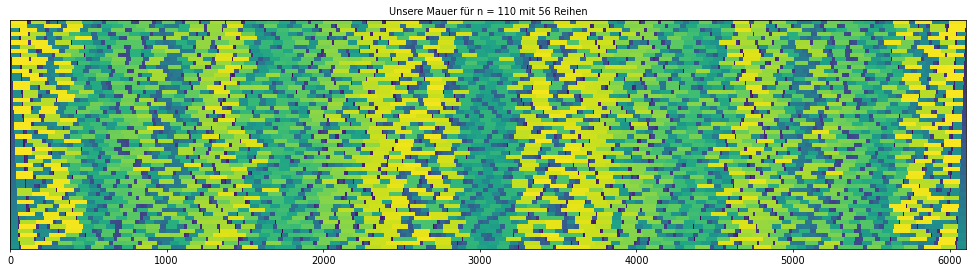

In [ ]:
for n in [14, 22]:
    print('n = %d:' % n)
    zeige(beste[n][0])
    print()

fig, achse = plt.subplots(figsize=(14, 4))
zeichne(achse, beste[110][0], 'Unsere Mauer für n = 110 mit 56 Reihen', zahlen=False)
plt.tight_layout()
plt.show()

Im Bild für n = 110 (gelb die langen, blau die kurzen Steine) sieht man das Spiegeln: Die rechte Hälfte ist das Spiegelbild der linken an
der Mitte bei etwa 3053, nur sind in jedem Paar die beiden Reihen vertauscht.

**Die Beispielmauer der Lösungshinweise.** Die Datei `mauer_n110.xlsx` ist ein ZIP-Archiv. Die Texte aller Zellen stehen darin in
`xl/sharedStrings.xml`, jeder zwischen `<t>` und `</t>`. Die Reihen der Mauer sind die Texte, die mit `__sum=` enden; davor stehen die 110
Steinlängen. Mit `re.findall` holen wir alle Texte heraus.

In [ ]:
import re
import zipfile

with zipfile.ZipFile('beispieldaten/mauer_n110.xlsx') as archiv:
    xml = archiv.read('xl/sharedStrings.xml').decode('utf-8', errors='replace')
texte = re.findall(r'<t[^>]*>(.*?)</t>', xml, re.DOTALL)
muster = []
for text in texte:
    if '__sum=' in text:
        muster.append([int(z) for z in text.split()[:-1]])
print(len(muster), 'Reihen mit je', len(muster[0]), 'Steinen, Schiedsrichter:', pruefe(muster, 110))
print('Erste Steine der Reihen:', [reihe[0] for reihe in muster[:8]], '...')
print('Reihe 1 endet mit', muster[0][-6:], ' Reihe 2 beginnt mit', muster[1][:6])
for text in texte:
    if text.startswith('Expand'):
        print(text.strip())

56 Reihen mit je 110 Steinen, Schiedsrichter: ok
Erste Steine der Reihen: [1, 2, 3, 4, 5, 6, 7, 8] ...
Reihe 1 endet mit [101, 44, 64, 20, 58, 2]  Reihe 2 beginnt mit [2, 58, 20, 64, 44, 101]
Expand()-Aufrufe: 461447


Auch die Musterlösung hat 56 Reihen, beginnt mit einer Treppe und ist gespiegelt: Reihe 1 endet mit dem Anfang von Reihe 2, rückwärts
gelesen. Unser Schiedsrichter findet keinen Fehler.

## Für Neugierige

**Vergleich mit den Lösungshinweisen.** Die Hinweise beschreiben ein Java-Programm und zählen auf, wie weit jede Verbesserung kommt
(maximale Mauern „in annehmbarer Zeit“):

| Verbesserung | Hinweise (Java) | dieses Notebook (Python) |
|---|---|---|
| Tiefensuche Spalte für Spalte | n = 14 | n = 14 (Version 2, 203250 Aufrufe) |
| zufällige Reihenfolgen | n = 22 | n = 16 und 20 nur mit sehr vielen Versuchen (Version 4) |
| Spiegeln | n = 38 | – (bei uns gleich mit dem Paar-Test zusammen) |
| Sackgassen erkennen | n = 102 | alle n = 4k + 2 bis 110 (Version 5) |
| Reihenfolgen ergänzen | n = 110, n = 114 nicht | nicht nötig für 110; n = 114 nicht gefunden (126 + 351 Versuche, zwei Startwerte) |

Unser Paar-Test ist das dritte Beispiel aus Abschnitt 1.5 der Hinweise; ob ihr Programm genau so prüft, steht dort nicht. Die letzte Zeile
ist ein weiterer Trick der Hinweise: Eine gute Reihenfolge für n = 102 wird an vier zufälligen Stellen um 103 bis 106 ergänzt und für
n = 106 benutzt. Den brauchten wir nicht. In der Tabelle der Hinweise stehen nur Werte `n = 4k + 2` (14, 22, 38, 102, 110); bei der
Laufzeit nennen sie auch n = 80 (unter zehn Sekunden), wie sie `n = 4k` ohne Spiegeln so weit schaffen, steht dort nicht. Die
Musterlösung für n = 110 brauchte nach der Datei 461447 Aufrufe.

**Warum ist n = 4k so viel schwerer?** Ohne Spiegeln muss die Suche die ganze Mauer bauen, doppelt so tief. Und gegen Ende muss jede Reihe
genau `n − 1` Fugen haben und ihr letzter Stein genau bis zum Rand reichen. In der gespiegelten Mauer ist das Ende dagegen ganz locker: Wann
eine Reihe in der linken Hälfte aufhört, ist egal, der Mittelstein passt immer. Beim Erstellen des Notebooks hat Version 4 für n = 16 1745
Versuche gebraucht (zusammen 1,7 Millionen Aufrufe), für n = 20 schon 9293 Versuche (9,3 Millionen Aufrufe), für n = 24 fand sie in 49490 Versuchen (57 Millionen Aufrufe) keine.

**Laufzeit.** Im schlimmsten Fall probiert die Suche fast alle Anordnungen durch; das sind bis zu `(n!)^h` viele, mehr als exponentiell
viele. Ein einzelner Aufruf von `lege` kostet bei Version 5 etwa `h/2` Vergleiche (einen pro Paar), das Sortieren der wenigen Kandidaten und
das Suchen der zwei längsten freien Steine eines Paares. Wie viele Aufrufe nötig sind, hängt stark vom Zufall ab, das zeigen die Tabellen oben: Bei n = 58 reichte ein Versuch mit 5463
Aufrufen, bei n = 50 waren es 15 Versuche. Im Mittel wächst die Zahl der Aufrufe, wie bei den Lösungshinweisen, ungefähr exponentiell mit n.
Die Grenze `n³/12` pro Versuch ist eine Faustregel der Hinweise: Ein Versuch, der nach so vielen Aufrufen noch keine Mauer hat, steckt
meistens in einer schlechten Ecke fest.

**Gibt es immer eine höchste Mauer?** Das weiß man nicht. Die Schranke aus Schritt 2 sagt nur, dass es höher nicht geht. Unser Programm
findet die höchste Mauer für alle n bis 23 und für alle n = 4k + 2 und 4k + 3 bis 110. Ob es für jedes n eine gibt, ist offen.

## Zum Schluss: Die Mauer mit MiniZinc

Die Aufgabe ist ein reines Suchproblem mit Bedingungen, also wie gemacht für MiniZinc. Die Variablen sind die Steine jeder Reihe
(`stein[r, i]`, ein 2D-Array) und die Fugen (`fuge[r, i]`, die Teilsummen). Die Bedingungen:
- In jeder Reihe kommt jede Länge genau einmal vor: `alldifferent` über die Steine einer Reihe.
- Die Fugen sind die Teilsummen: `fuge[r, i] = sum(j in 1..i)(stein[r, j])`.
- Keine Fuge doppelt: **ein** `alldifferent` über alle `h·(n − 1)` Fugen der Mauer.
- Wie in Version 2 ist die Reihenfolge der Reihen egal. Damit MiniZinc nicht dieselbe Mauer in allen Reihenfolgen durchprobiert, verlangen
  wir, dass die ersten Steine von oben nach unten größer werden. (Die Treppe 1, 2, 3, … verlangen wir **nicht**, sie ist nur eine Faustregel.)

Neu gegenüber den Arbeitsblättern ist nur `show_int(3, x)` in der Ausgabe: die Zahl x, rechtsbündig mit 3 Zeichen.
```minizinc
include "globals.mzn";

int: n;                                        % aus der Datendatei
int: h = n div 2 + 1;                          % so viele Reihen
int: L = n * (n + 1) div 2;                    % Länge einer Reihe

array[1..h, 1..n] of var 1..n: stein;          % stein[r, i]: Länge des i-ten Steins in Reihe r
array[1..h, 1..n-1] of var 1..L-1: fuge;       % fuge[r, i]: Stelle der Fuge hinter dem i-ten Stein

constraint forall(r in 1..h)(alldifferent([stein[r, i] | i in 1..n]));          % jede Länge einmal pro Reihe
constraint forall(r in 1..h, i in 1..n-1)(fuge[r, i] = sum(j in 1..i)(stein[r, j]));
constraint alldifferent([fuge[r, i] | r in 1..h, i in 1..n-1]);                 % keine Fuge doppelt
constraint forall(r in 1..h-1)(stein[r, 1] < stein[r + 1, 1]);                  % Reihen sortiert

solve satisfy;

output [show_int(3, stein[r, i]) ++ if i == n then "\n" else "" endif | r in 1..h, i in 1..n];
```

Die Datendatei enthält nur n, zum Beispiel `n = 10;`. Die kleine Funktion `als_dzn` schreibt sie:

In [ ]:
def als_dzn(n):
    return 'n = %d;' % n


print(als_dzn(10))

n = 10;


**Ausgabe von Gecode für n = 10** (in weniger als einer Sekunde):

**Ausgabe:**

```
1  6  5  4  7  8  9  3 10  2
  2  6  7  4  9  8  3 10  1  5
  3  6  5  8  4  7  9 10  2  1
  4  6  7  3  5  9 10  2  1  8
  5  6  7  9  8  2  1 10  3  4
  6  7  8  3  5  1  2  9  4 10
----------
```

Wir prüfen die Mauer von MiniZinc mit unserem Schiedsrichter:

In [ ]:
mauer_minizinc = [
    [1, 6, 5, 4, 7, 8, 9, 3, 10, 2],
    [2, 6, 7, 4, 9, 8, 3, 10, 1, 5],
    [3, 6, 5, 8, 4, 7, 9, 10, 2, 1],
    [4, 6, 7, 3, 5, 9, 10, 2, 1, 8],
    [5, 6, 7, 9, 8, 2, 1, 10, 3, 4],
    [6, 7, 8, 3, 5, 1, 2, 9, 4, 10],
]
print(len(mauer_minizinc), 'Reihen, Schiedsrichter:', pruefe(mauer_minizinc, 10))

6 Reihen, Schiedsrichter: ok


**Wie weit kommt MiniZinc?** Beim Erstellen des Notebooks haben wir das Modell für n von 4 bis 30 mit einer Minute Zeitlimit laufen
lassen (Gecode für alle diese n, Chuffed und CP-SAT für die geraden n bis 16):
- **Gecode** ist bis n = 15 jeweils in etwa einer Sekunde fertig, n = 16 dauert 17 Sekunden, n = 18 knapp 10 Sekunden; die ungeraden n
  17 und 19 gehen wieder sofort (dort ist mehr Platz, weil Stellen frei bleiben dürfen). Ab n = 20 und ab n = 21 findet Gecode in einer
  Minute nichts mehr.
- **Chuffed** schafft die geraden n bis 12 (in höchstens 6 Sekunden), ab n = 14 nichts mehr in einer Minute.
- **CP-SAT** schafft n = 14 in 11 Sekunden; bei n = 16 hielt es sich nicht an das Zeitlimit, wir mussten den Prozess beenden.

Das ist etwa so weit wie Version 2 und 3, also ohne Spiegeln. Mit Zufall und Neustarts (Version 4) kamen wir bis n = 20.

**Spiegeln in MiniZinc.** Aus Schritt 7 wissen wir: Bei der gespiegelten Mauer ist Reihe 2 einfach Reihe 1 rückwärts, Reihe 4 ist Reihe 3
rückwärts usw. Das ist in MiniZinc eine einzige Zeile: `stein[2 * p, i] = stein[2 * p - 1, n + 1 - i]`. Das Sortieren der Reihen passen
wir an: Innerhalb eines Paares und von Paar zu Paar werden die ersten Steine größer (alle Reihen zu sortieren, könnte gespiegelte Mauern
verbieten). Statt der Zeile „Reihen sortiert“ stehen im Modell also diese drei Zeilen (für n = 4k + 2):
```minizinc
constraint forall(p in 1..h div 2, i in 1..n)(stein[2 * p, i] = stein[2 * p - 1, n + 1 - i]);   % Reihe 2p = Reihe 2p-1 rückwärts
constraint forall(p in 1..h div 2)(stein[2 * p - 1, 1] < stein[2 * p, 1]);                       % im Paar sortiert
constraint forall(p in 1..h div 2 - 1)(stein[2 * p - 1, 1] < stein[2 * p + 1, 1]);               % Paare sortiert
```

**Ausgabe von Gecode für n = 22 mit Spiegeln** (etwa eine Sekunde; unser Schiedsrichter findet keinen Fehler):

**Ausgabe:**

```
1 11 14 15  7  6 21 19 18 20  4 22  3  5  2 17  9 16 12  8 10 13
 13 10  8 12 16  9 17  2  5  3 22  4 20 18 19 21  6  7 15 14 11  1
  2 12 14 10  9 19  7 17  8  1 21 22  4  3 18  6 20  5 16 15 13 11
 11 13 15 16  5 20  6 18  3  4 22 21  1  8 17  7 19  9 10 14 12  2
  3 12 14 15 18  8  9 22  5 17  2  6  4 21  1 19 20  7 16 13 11 10
 10 11 13 16  7 20 19  1 21  4  6  2 17  5 22  9  8 18 15 14 12  3
  4 12 11 10 16 21 17 18  1  3  2 22  8 19  5  6 20  7 15 14 13  9
  9 13 14 15  7 20  6  5 19  8 22  2  3  1 18 17 21 16 10 11 12  4
  5 12 13 15 18  6  3 16 17 22  2 21  1 19  7 20  4 10  9 14 11  8
  8 11 14  9 10  4 20  7 19  1 21  2 22 17 16  3  6 18 15 13 12  5
  6 12 14  8  9 16  2  4 22 21 20 19 18  1 17  3 15 11 10  5 13  7
  7 13  5 10 11 15  3 17  1 18 19 20 21 22  4  2 16  9  8 14 12  6
----------
```

Gemessen beim Erstellen (eine Minute Zeitlimit, alle n = 4k + 2 von 6 bis 62):
- **Gecode** findet die gespiegelten Mauern bis n = 38 jeweils in höchstens 2 Sekunden. Für 42 bis 58 findet es in einer Minute nichts,
  für 62 dann wieder in 8 Sekunden: Ob die Suche schnell eine gute Ecke erwischt, ist auch hier Glückssache.
- **Chuffed** schafft n = 10 bis 22, ab 26 nicht mehr; ab 34 hielt es sich nicht an das Zeitlimit.
- **CP-SAT** schafft n = 10 und 14; ab 18 hielt es sich nicht an das Zeitlimit.

Das Spiegeln hilft MiniZinc also genauso wie unserem Programm: Gecode kommt von 18 auf 38, so weit wie die Lösungshinweise mit ihrem
Spiegeltrick, bevor sie Sackgassen erkannten. Version 5 kommt viel weiter, weil Treppe, gewürfelte Reihenfolge, Neustarts und der
Paar-Test die Suche stark lenken. Von all dem weiß das MiniZinc-Modell nichts.